# 01 — FP8 basics: sign, exponent, mantissa

Goal: understand what FP8 is, how the two formats (`float8_e4m3fn`, `float8_e5m2`) differ,
and verify what **this Mac (MPS) with PyTorch 2.15** actually supports.

```
value = (-1)^sign × 2^(exponent − bias) × 1.mantissa₂
```

## 1. Environment

In [1]:
import platform

import torch
import torch.nn.functional as F

print("torch      :", torch.__version__)
print("macOS      :", platform.mac_ver()[0], platform.machine())
print("MPS built  :", torch.backends.mps.is_built())
print("MPS avail  :", torch.backends.mps.is_available())
DEV = "mps" if torch.backends.mps.is_available() else "cpu"
print("device     :", DEV)

torch      : 2.15.0
macOS      : 26.7.1 arm64
MPS built  : True
MPS avail  : True
device     : mps


## 2. Decode 8 bits by hand

The helper below decodes any FP8 bit pattern manually, and we compare it with what PyTorch says
by reinterpreting the same byte as the FP8 dtype (`.view(dtype)`).

In [2]:
FORMATS = {
    "e4m3fn": dict(exp_bits=4, man_bits=3, bias=7, dtype=torch.float8_e4m3fn),
    "e5m2": dict(exp_bits=5, man_bits=2, bias=15, dtype=torch.float8_e5m2),
}


def decode(bits: str, fmt: str) -> float:
    """Decode a bit string like '0 1000 100' (normal numbers only)."""
    f = FORMATS[fmt]
    b = bits.replace(" ", "")
    assert len(b) == 8
    sign = -1 if b[0] == "1" else 1
    e = int(b[1 : 1 + f["exp_bits"]], 2)
    m = b[1 + f["exp_bits"] :]
    mantissa = 1 + sum(int(bit) / 2 ** (i + 1) for i, bit in enumerate(m))  # hidden leading 1
    print(f"{fmt:7s} {bits}: sign={sign:+d}  2^({e}-{f['bias']})={2.0 ** (e - f['bias'])}  1.{m}₂={mantissa}")
    return sign * 2.0 ** (e - f["bias"]) * mantissa


def torch_decode(bits: str, fmt: str) -> float:
    byte = torch.tensor([int(bits.replace(" ", ""), 2)], dtype=torch.uint8)
    return byte.view(FORMATS[fmt]["dtype"]).float().item()


for bits, fmt in [("0 1000 100", "e4m3fn"), ("0 1010 011", "e4m3fn"), ("0 10000 10", "e5m2"), ("1 0111 000", "e4m3fn")]:
    print(f"   by hand = {decode(bits, fmt)}   torch = {torch_decode(bits, fmt)}\n")

e4m3fn  0 1000 100: sign=+1  2^(8-7)=2.0  1.100₂=1.5
   by hand = 3.0   torch = 3.0

e4m3fn  0 1010 011: sign=+1  2^(10-7)=8.0  1.011₂=1.375
   by hand = 11.0   torch = 11.0

e5m2    0 10000 10: sign=+1  2^(16-15)=2.0  1.10₂=1.5
   by hand = 3.0   torch = 3.0

e4m3fn  1 0111 000: sign=-1  2^(7-7)=1.0  1.000₂=1.0
   by hand = -1.0   torch = -1.0



## 3. The two formats side by side (`torch.finfo`)

In [3]:
for dt in (torch.float8_e4m3fn, torch.float8_e5m2, torch.bfloat16, torch.float16):
    fi = torch.finfo(dt)
    print(
        f"{str(dt):22s} bits={fi.bits:2d}  max={fi.max:>12.6g}  smallest_normal={fi.smallest_normal:.3g}  eps={fi.eps}"
    )

torch.float8_e4m3fn    bits= 8  max=         448  smallest_normal=0.0156  eps=0.125
torch.float8_e5m2      bits= 8  max=       57344  smallest_normal=6.1e-05  eps=0.25
torch.bfloat16         bits=16  max= 3.38953e+38  smallest_normal=1.18e-38  eps=0.0078125
torch.float16          bits=16  max=       65504  smallest_normal=6.1e-05  eps=0.0009765625


## 4. All representable values between 1 and 4

3 mantissa bits → 2³ = 8 values per power of 2; 2 mantissa bits → 2² = 4.

In [4]:
def all_values(dt: torch.dtype) -> torch.Tensor:
    v = torch.arange(256, dtype=torch.uint8).view(dt).float()
    return v[torch.isfinite(v)].unique()


for dt in (torch.float8_e4m3fn, torch.float8_e5m2):
    v = all_values(dt)
    print(f"{str(dt):20s} {len(v)} finite values | in [1,4): {v[(v >= 1) & (v < 4)].tolist()}")

torch.float8_e4m3fn  253 finite values | in [1,4): [1.0, 1.125, 1.25, 1.375, 1.5, 1.625, 1.75, 1.875, 2.0, 2.25, 2.5, 2.75, 3.0, 3.25, 3.5, 3.75]
torch.float8_e5m2    247 finite values | in [1,4): [1.0, 1.25, 1.5, 1.75, 2.0, 2.5, 3.0, 3.5]


## 5. Same inputs, different rounding

In [5]:
x = torch.tensor([1.1, 3.0, 300.0, 448.0, 500.0, 10000.0])
print("input   :", x.tolist())
for dt in (torch.float8_e4m3fn, torch.float8_e5m2):
    print(f"{str(dt)[13:]:8s}:", x.to(dt).float().tolist())

input   : [1.100000023841858, 3.0, 300.0, 448.0, 500.0, 10000.0]
e4m3fn  : [1.125, 3.0, 288.0, 448.0, 448.0, 448.0]
e5m2    : [1.0, 3.0, 320.0, 448.0, 512.0, 10240.0]


## 5b. Seeing the formats

Each chart below is also saved to `docs/images/` so the README can embed it.

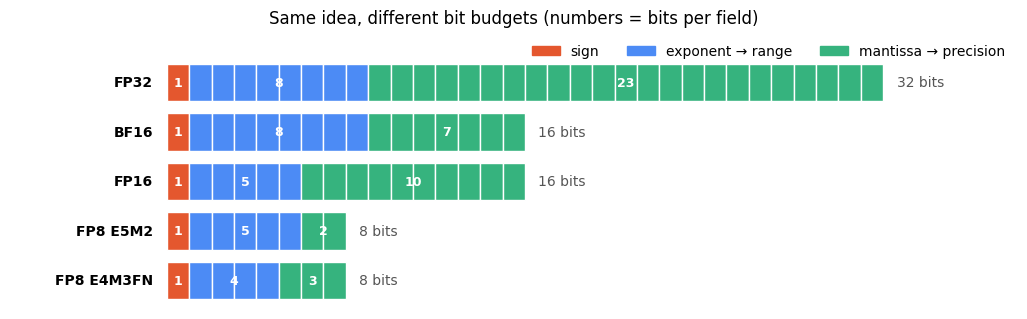

In [6]:
import subprocess
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyproject.toml").exists())
IMG = ROOT / "docs" / "images"
IMG.mkdir(parents=True, exist_ok=True)
CHIP = subprocess.run(["sysctl", "-n", "machdep.cpu.brand_string"], capture_output=True, text=True).stdout.strip()
FMT_COLORS = {"FP16": "#9b59b6", "BF16": "#f39c12", "FP8 E5M2": "#e74c3c", "FP8 E4M3FN": "#2e86de"}
FMT_DTYPES = {
    "FP16": torch.float16,
    "BF16": torch.bfloat16,
    "FP8 E5M2": torch.float8_e5m2,
    "FP8 E4M3FN": torch.float8_e4m3fn,
}


def save(fig: plt.Figure, name: str) -> None:
    fig.savefig(IMG / name, dpi=150, bbox_inches="tight")
    plt.show()


# name -> (exponent bits, mantissa bits)
LAYOUTS = {"FP32": (8, 23), "BF16": (8, 7), "FP16": (5, 10), "FP8 E5M2": (5, 2), "FP8 E4M3FN": (4, 3)}
PART_COLORS = {"sign": "#e4572e", "exponent": "#4c8bf5", "mantissa": "#36b37e"}

fig, ax = plt.subplots(figsize=(13, 3.6))
for row, (name, (e, m)) in enumerate(LAYOUTS.items()):
    y = len(LAYOUTS) - 1 - row
    col = 0
    for part, n in (("sign", 1), ("exponent", e), ("mantissa", m)):
        for i in range(n):
            ax.add_patch(plt.Rectangle((col + i, y), 1, 0.75, facecolor=PART_COLORS[part], edgecolor="white"))
        ax.text(col + n / 2, y + 0.37, str(n), ha="center", va="center", color="white", fontweight="bold", fontsize=9)
        col += n
    ax.text(-0.6, y + 0.37, name, ha="right", va="center", fontweight="bold")
    ax.text(col + 0.6, y + 0.37, f"{1 + e + m} bits", va="center", color="#555")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in PART_COLORS.values()]
ax.legend(handles, ["sign", "exponent → range", "mantissa → precision"], loc="upper right", ncol=3, frameon=False)
ax.set_xlim(-7, 38)
ax.set_ylim(-0.2, len(LAYOUTS) + 0.4)
ax.axis("off")
ax.set_title("Same idea, different bit budgets (numbers = bits per field)")
save(fig, "01_bit_layouts.png")

### Where the representable values live

Left: every positive FP8 value as a tick. Right: the gap to the next representable value. The gap doubles every
power of 2, so **relative** precision is constant but **absolute** precision gets worse as numbers grow.
Each line ends at that format's max value.

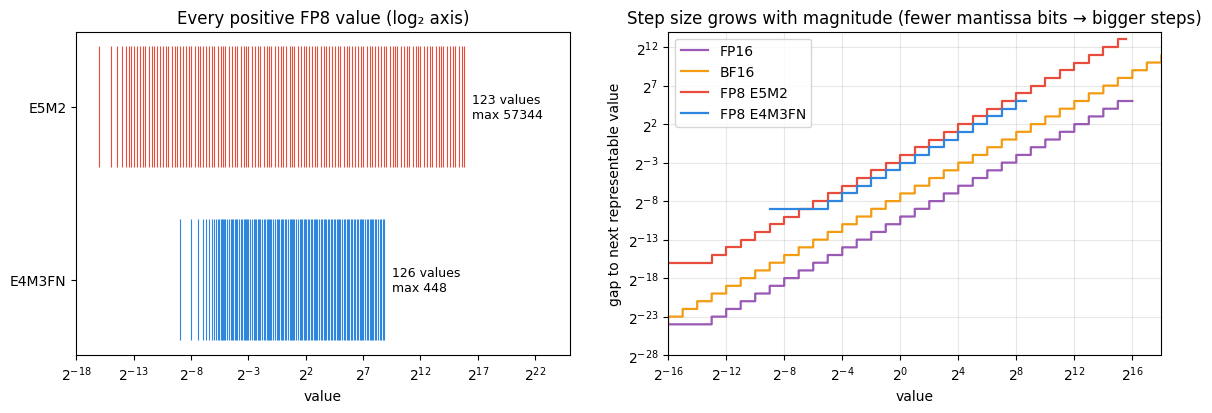

In [7]:
def positive_finite(dt: torch.dtype) -> torch.Tensor:
    """All positive finite values of a float dtype, sorted. Shape: [n_values]."""
    raw = (
        torch.arange(256, dtype=torch.uint8)
        if torch.finfo(dt).bits == 8
        else torch.arange(-32768, 32768, dtype=torch.int16)
    )
    v = raw.view(dt).float()
    return v[torch.isfinite(v) & (v > 0)].unique()


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.2))
for i, name in enumerate(("FP8 E4M3FN", "FP8 E5M2")):
    v = positive_finite(FMT_DTYPES[name]).numpy()
    ax1.vlines(v, i - 0.35, i + 0.35, color=FMT_COLORS[name], lw=0.8)
    ax1.text(v.max() * 1.6, i, f"{len(v)} values\nmax {v.max():g}", va="center", fontsize=9)
ax1.set_xscale("log", base=2)
ax1.set_yticks([0, 1], ["E4M3FN", "E5M2"])
ax1.set_xlim(2**-18, 2**25)
ax1.set_title("Every positive FP8 value (log₂ axis)")
ax1.set_xlabel("value")

for name, dt in FMT_DTYPES.items():
    v = positive_finite(dt).numpy()
    ax2.step(v[:-1], np.diff(v), where="post", color=FMT_COLORS[name], label=name, lw=1.6)
ax2.set_xscale("log", base=2)
ax2.set_yscale("log", base=2)
ax2.set_xlim(2**-16, 2**18)
ax2.set_ylim(2**-28, 2**14)
ax2.set_xlabel("value")
ax2.set_ylabel("gap to next representable value")
ax2.set_title("Step size grows with magnitude (fewer mantissa bits → bigger steps)")
ax2.legend()
ax2.grid(alpha=0.3)
save(fig, "01_value_spacing.png")

### Rounding error across the whole range

Cast 40,000 log-spaced values to each format and plot the worst relative error in each bin. The flat band in the middle is the format's
precision (~6% for E4M3FN, ~12% for E5M2, <1% for 16-bit). The walls at 100% are **underflow** (flushed to 0) on the
left and **overflow** (`inf` or clamped to 448) on the right.

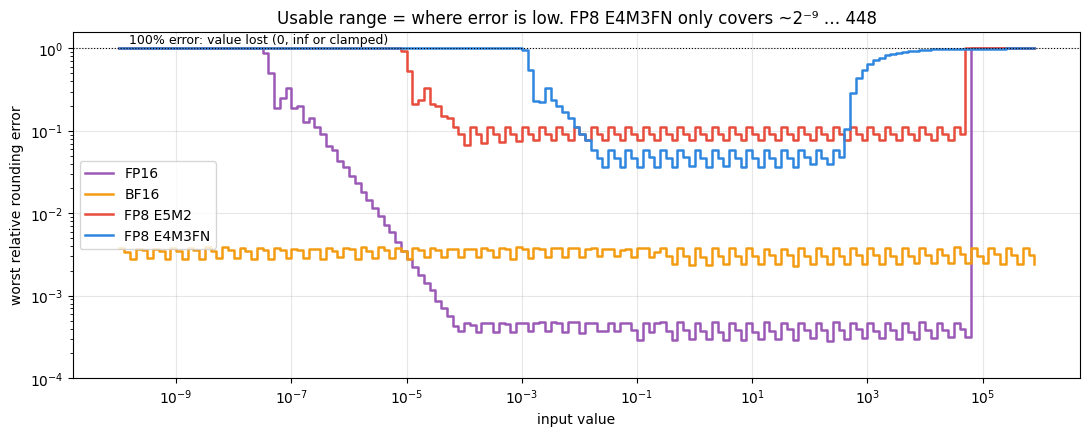

In [8]:
x = torch.logspace(-10, 6, 40000)
edges = np.logspace(-10, 6, 161)
bin_of = np.digitize(x.numpy(), edges) - 1
fig, ax = plt.subplots(figsize=(13, 4.5))
for name, dt in FMT_DTYPES.items():
    q = x.to(dt).float()
    err = ((q - x).abs() / x).nan_to_num(nan=1.0, posinf=1.0).clamp(max=1.0).numpy()
    worst = np.array([err[bin_of == b].max() for b in range(len(edges) - 1)])  # worst error per bin
    ax.step(edges[:-1], worst, where="post", color=FMT_COLORS[name], lw=1.8, label=name)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_ylim(1e-4, 1.6)
ax.axhline(1.0, color="k", ls=":", lw=0.8)
ax.text(1.5e-10, 1.15, "100% error: value lost (0, inf or clamped)", fontsize=9)
ax.set_xlabel("input value")
ax.set_ylabel("worst relative rounding error")
ax.set_title("Usable range = where error is low. FP8 E4M3FN only covers ~2⁻⁹ … 448")
ax.legend(loc="center left")
ax.grid(alpha=0.3)
save(fig, "01_rounding_error.png")

Note: PyTorch's `.to(fp8)` **saturates** — 500 and 10000 both clamp to 448 in `e4m3fn`.
No error, no warning: large values are silently destroyed. That's one reason we scale before casting.

## 6. What works on MPS on this machine?

Each check is run independently so one failure doesn't hide the others.

In [9]:
def check(label: str, fn) -> None:
    try:
        print(f"  OK    {label:38s} -> {fn()}")
    except Exception as e:  # exploration notebook: report, don't stop
        print(f"  FAIL  {label:38s} -> {type(e).__name__}: {str(e).splitlines()[0][:90]}")


x = torch.tensor([1.1, 3.0, 300.0])
for dt in (torch.float8_e4m3fn, torch.float8_e5m2):
    print(dt)
    check("cast to FP8 on MPS + back", lambda: x.to(DEV).to(dt).float().cpu().tolist())
    check("tensor.device after cast", lambda: x.to(DEV).to(dt).device)
    check("elementwise add (a + a)", lambda: (x.to(DEV).to(dt) + x.to(DEV).to(dt)).dtype)

torch.float8_e4m3fn
  OK    cast to FP8 on MPS + back              -> [1.125, 3.0, 288.0]
  OK    tensor.device after cast               -> mps:0
  FAIL  elementwise add (a + a)                -> RuntimeError: Failed to create function state object for: add_dense_float8_e4m3fn_float8_e4m3fn
torch.float8_e5m2
  FAIL  cast to FP8 on MPS + back              -> RuntimeError: Undefined type Float8_e5m2
  FAIL  tensor.device after cast               -> RuntimeError: Undefined type Float8_e5m2
  FAIL  elementwise add (a + a)                -> RuntimeError: Undefined type Float8_e5m2


### Why does `a + a` fail on MPS?

Metal kernels are compiled per dtype. In 2.15 the FP8 binary kernels were only instantiated for `eq` and `ne`
(`REGISTER_FP8_EQ_OP` in `BinaryKernel.metal`), so `add` finds no `add_dense_float8_e4m3fn_float8_e4m3fn` kernel.
This is by design: FP8 is a storage/matmul format, not an arithmetic one (CPU doesn't support `+` either).
The pattern is **upcast → compute → (optionally) cast back**.

In [10]:
a = torch.tensor([1.0, 2.0, 3.0], device=DEV).to(torch.float8_e4m3fn)
check("a == a", lambda: (a == a).tolist())
check("a + a", lambda: (a + a).float().tolist())
check("a * a", lambda: (a * a).float().tolist())
check("upcast to bf16, then add", lambda: (a.bfloat16() + a.bfloat16()).float().tolist())

  OK    a == a                                 -> [True, True, True]
  FAIL  a + a                                  -> RuntimeError: Failed to create function state object for: add_dense_float8_e4m3fn_float8_e4m3fn
  FAIL  a * a                                  -> RuntimeError: Failed to create function state object for: mul_dense_float8_e4m3fn_float8_e4m3fn
  OK    upcast to bf16, then add               -> [2.0, 4.0, 6.0]


### Scaled matmul: which FP8 combinations does MPS support?

`F.scaled_mm` (new 2.15 API) and legacy `torch._scaled_mm`. Scales here are just `1.0`
— we'll cover real scaling in the next notebook.

In [11]:
E4, E5 = torch.float8_e4m3fn, torch.float8_e5m2
one = torch.tensor(1.0, device=DEV)


def make(da: torch.dtype, db: torch.dtype) -> tuple[torch.Tensor, torch.Tensor]:
    a = torch.randn(64, 128, device=DEV).to(da)  # [M, K]
    b = torch.randn(32, 128, device=DEV).to(db).t()  # [K, N], column-major
    return a, b


for da, db in [(E4, E4), (E4, E5), (E5, E4), (E5, E5)]:
    name = f"{str(da)[13:]} @ {str(db)[13:]}"
    print(name)
    check(
        "F.scaled_mm (tensorwise)",
        lambda: F.scaled_mm(*make(da, db), one, F.ScalingType.TensorWise, one, F.ScalingType.TensorWise).shape,
    )
    check(
        "torch._scaled_mm (legacy)", lambda: torch._scaled_mm(*make(da, db), one, one, out_dtype=torch.bfloat16).shape
    )

e4m3fn @ e4m3fn
  OK    F.scaled_mm (tensorwise)               -> torch.Size([64, 32])
  FAIL  torch._scaled_mm (legacy)              -> NotImplementedError: The operator 'aten::_scaled_mm' is not currently implemented for the MPS device. If you wa
e4m3fn @ e5m2
  FAIL  F.scaled_mm (tensorwise)               -> RuntimeError: Undefined type Float8_e5m2
  FAIL  torch._scaled_mm (legacy)              -> RuntimeError: Undefined type Float8_e5m2
e5m2 @ e4m3fn
  FAIL  F.scaled_mm (tensorwise)               -> RuntimeError: Undefined type Float8_e5m2
  FAIL  torch._scaled_mm (legacy)              -> RuntimeError: Undefined type Float8_e5m2
e5m2 @ e5m2
  FAIL  F.scaled_mm (tensorwise)               -> RuntimeError: Undefined type Float8_e5m2
  FAIL  torch._scaled_mm (legacy)              -> RuntimeError: Undefined type Float8_e5m2


## 7. What 2.15 introduced vs. what already existed

Sourced from the official release notes (`gh release view v2.X.0 -R pytorch/pytorch`) and the
[2.15 MPS kernel source](https://github.com/pytorch/pytorch/blob/v2.15.0/aten/src/ATen/native/mps/operations/ScaledMM.mm).

| Version | FP8 milestone | Platform |
|---|---|---|
| 2.1 | `float8_e4m3fn`, `float8_e5m2` dtypes; `torch._scaled_mm` | CPU casts, CUDA (H100/Ada) |
| 2.2 | `float8_e4m3fnuz`, `float8_e5m2fnuz` (AMD variants) | ROCm |
| 2.7 | `float8_e8m0fnu` (power-of-2 scale dtype for MX formats) | — |
| 2.10 | **`F.scaled_mm`** + `torch._scaled_mm_v2` (recipe-based API with `ScalingType`) | CUDA, XPU |
| 2.12 | `_scaled_mm_v2` CPU implementation | CPU |
| **2.15** | **`float8_e4m3fn` on MPS** (#194074) and **`F.scaled_mm` on MPS** (#196916), tensorwise + rowwise, gemv fast path | **MPS** |

So in 2.15 the *format* and the *API* are not new — what's new is that **MPS can hold FP8 tensors
and run `F.scaled_mm` natively**.

From the MPS kernel source, the constraints are:
- inputs: **only `float8_e4m3fn`** for both operands (no `e5m2`)
- scaling: **TensorWise** or **RowWise** only (no block-wise / MX), FP32 scales, no swizzle
- outputs: `float32`, `float16`, `bfloat16`, or `float8_e4m3fn`
- `K` and `N` must be aligned (multiples of 16)

Caveat: the blog says "`_scaled_mm`", but the legacy `torch._scaled_mm` op is **not** registered for MPS
(see section 6) — only the v2 path behind `F.scaled_mm` is.

In [12]:
ST = F.ScalingType


def fp8_pair(m: int, k: int = 128, n: int = 32) -> tuple[torch.Tensor, torch.Tensor]:
    a = torch.randn(m, k, device=DEV).to(E4)  # [M, K]
    b = torch.randn(n, k, device=DEV).to(E4).t()  # [K, N]
    return a, b


for m in (64, 1):  # m=1 is a decode-sized shape -> gemv fast path
    a, b = fp8_pair(m)
    print(f"M={m}")
    check("TensorWise scales: scalar, scalar", lambda: F.scaled_mm(a, b, one, ST.TensorWise, one, ST.TensorWise).shape)
    check(
        "RowWise scales: [M,1], [1,N]",
        lambda: F.scaled_mm(
            a, b, torch.ones(m, 1, device=DEV), ST.RowWise, torch.ones(1, 32, device=DEV), ST.RowWise
        ).shape,
    )
    for out in (torch.float32, torch.float16, torch.bfloat16):
        check(
            f"output_dtype={out}",
            lambda: F.scaled_mm(a, b, one, ST.TensorWise, one, ST.TensorWise, output_dtype=out).dtype,
        )

print("Unsupported on MPS (expected to fail):")
a, b = fp8_pair(64, k=100)
check("K=100 (not aligned to 16)", lambda: F.scaled_mm(a, b, one, ST.TensorWise, one, ST.TensorWise).shape)

M=64
  OK    TensorWise scales: scalar, scalar      -> torch.Size([64, 32])
  OK    RowWise scales: [M,1], [1,N]           -> torch.Size([64, 32])
  OK    output_dtype=torch.float32             -> torch.float32


  OK    output_dtype=torch.float16             -> torch.float16
  OK    output_dtype=torch.bfloat16            -> torch.bfloat16
M=1
  OK    TensorWise scales: scalar, scalar      -> torch.Size([1, 32])
  OK    RowWise scales: [M,1], [1,N]           -> torch.Size([1, 32])
  OK    output_dtype=torch.float32             -> torch.float32
  OK    output_dtype=torch.float16             -> torch.float16
  OK    output_dtype=torch.bfloat16            -> torch.bfloat16
Unsupported on MPS (expected to fail):
  FAIL  K=100 (not aligned to 16)              -> ValueError: Expected K and N to be divisible by 16 but got mat_a shape [64, 100] and mat_b shape [100,


### For contrast: CPU (since 2.12) accepts `e5m2` too

So the MPS restriction to `e4m3fn` is a backend limitation, not a PyTorch-wide one.

In [13]:
a5 = torch.randn(16, 32).to(torch.float8_e5m2)
b5 = torch.randn(16, 32).to(torch.float8_e5m2).t()
one_cpu = torch.tensor(1.0)
check("CPU F.scaled_mm e5m2 @ e5m2", lambda: F.scaled_mm(a5, b5, one_cpu, ST.TensorWise, one_cpu, ST.TensorWise).shape)
check(
    "CPU torch._scaled_mm e4m3fn (legacy)",
    lambda: torch._scaled_mm(a5.to(E4), b5.to(E4), one_cpu, one_cpu, out_dtype=torch.bfloat16).shape,
)

  OK    CPU F.scaled_mm e5m2 @ e5m2            -> torch.Size([16, 16])
  OK    CPU torch._scaled_mm e4m3fn (legacy)   -> torch.Size([16, 16])


## 8. Impact: memory, accuracy, speed

What do you actually gain by storing weights in FP8 on this Mac? Memory is exact. Accuracy and speed below are
**measured natively on MPS** with `F.scaled_mm` (no CPU fallback). Scaling is introduced properly in notebook 02;
here we use a simple one-scale-per-tensor recipe.

FP32           64.00 MiB on MPS for a 4096x4096 weight
BF16           32.00 MiB on MPS for a 4096x4096 weight
FP8 + scale    16.00 MiB on MPS for a 4096x4096 weight


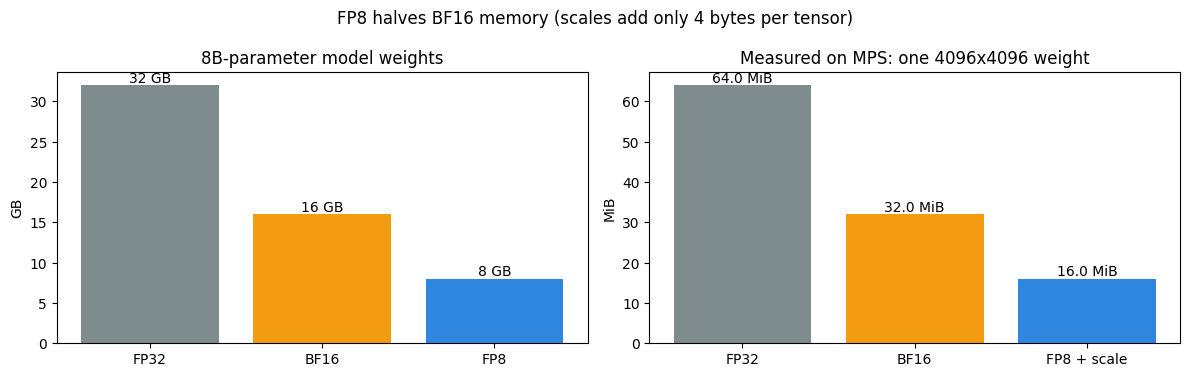

In [14]:
def fp8_tensorwise(x: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor]:
    """Quantize to FP8 with one FP32 scale. Returns (fp8 values [same shape], scale [])."""
    scale = (x.abs().amax().float() / torch.finfo(E4).max).clamp(min=1e-12)
    return (x.float() / scale).to(E4), scale


def allocated_bytes(make) -> int:
    """MPS bytes held by the tensor `make()` returns (temporaries are freed first)."""
    torch.mps.synchronize()
    before = torch.mps.current_allocated_memory()
    t = make()
    torch.mps.synchronize()
    used = torch.mps.current_allocated_memory() - before
    del t
    return used


K = N = 4096
measured = {
    "FP32": allocated_bytes(lambda: torch.randn(N, K, device=DEV)),
    "BF16": allocated_bytes(lambda: torch.randn(N, K, device=DEV, dtype=torch.bfloat16)),
    "FP8 + scale": allocated_bytes(lambda: fp8_tensorwise(torch.randn(N, K, device=DEV))),
}
for k, v in measured.items():
    print(f"{k:12s} {v / 2**20:7.2f} MiB on MPS for a {N}x{K} weight")

PARAMS = 8e9  # an 8B-parameter LLM, weights only
model_gb = {"FP32": 4 * PARAMS / 1e9, "BF16": 2 * PARAMS / 1e9, "FP8": 1 * PARAMS / 1e9}
colors = ["#7f8c8d", FMT_COLORS["BF16"], FMT_COLORS["FP8 E4M3FN"]]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.8))
bars = ax1.bar(model_gb.keys(), model_gb.values(), color=colors)
ax1.bar_label(bars, fmt="%.0f GB")
ax1.set_title("8B-parameter model weights")
ax1.set_ylabel("GB")
bars = ax2.bar(measured.keys(), [v / 2**20 for v in measured.values()], color=colors)
ax2.bar_label(bars, fmt="%.1f MiB")
ax2.set_title(f"Measured on MPS: one {N}x{K} weight")
ax2.set_ylabel("MiB")
fig.suptitle("FP8 halves BF16 memory (scales add only 4 bytes per tensor)")
fig.tight_layout()
save(fig, "01_impact_memory.png")

### Accuracy: matmul error vs an FP32 reference

`[256 x 4096] @ [4096 x 4096]` with LLM-like weights (`N(0, 0.02)`). FP8 costs roughly **10x more error than BF16**
(a few percent vs a fraction of a percent). Here "no scaling" is only slightly worse because these particular values
happen to sit near FP8's range — notebook 02 shows inputs where skipping the scale breaks badly.

FP16 mm                relative error = 0.0359%
BF16 mm                relative error = 0.2879%
FP8 no scaling         relative error = 4.2394%
FP8 tensorwise scale   relative error = 3.7435%


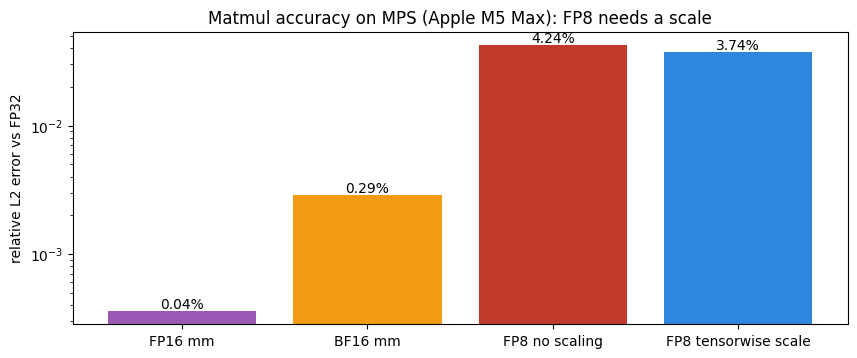

In [15]:
torch.manual_seed(0)
A = torch.randn(256, 4096, device=DEV)
W = torch.randn(4096, 4096, device=DEV) * 0.02
ref = A @ W.t()


def rel_err(y: torch.Tensor) -> float:
    return ((y.float() - ref).norm() / ref.norm()).item()


a8, sa = fp8_tensorwise(A)
w8, sw = fp8_tensorwise(W)
errors = {
    "FP16 mm": rel_err(A.half() @ W.half().t()),
    "BF16 mm": rel_err(A.bfloat16() @ W.bfloat16().t()),
    "FP8 no scaling": rel_err(F.scaled_mm(A.to(E4), W.to(E4).t(), one, ST.TensorWise, one, ST.TensorWise)),
    "FP8 tensorwise scale": rel_err(F.scaled_mm(a8, w8.t(), sa, ST.TensorWise, sw, ST.TensorWise)),
}
for k, v in errors.items():
    print(f"{k:22s} relative error = {v:.4%}")

fig, ax = plt.subplots(figsize=(10, 3.8))
bars = ax.bar(
    errors.keys(), errors.values(), color=[FMT_COLORS["FP16"], FMT_COLORS["BF16"], "#c0392b", FMT_COLORS["FP8 E4M3FN"]]
)
ax.bar_label(bars, labels=[f"{v:.2%}" for v in errors.values()])
ax.set_yscale("log")
ax.set_ylabel("relative L2 error vs FP32")
ax.set_title(f"Matmul accuracy on MPS ({CHIP}): FP8 needs a scale")
save(fig, "01_impact_accuracy.png")

### Speed: native MPS kernels, synchronized timing

`x @ Wᵀ` with `K = N = 4096`, for decode (M=1), small batches (M=4, 16) and prefill (M=2048).
"FP8 + quantize x" also includes computing the activation scale and casting it every call (dynamic scaling).
Median of 7 runs × 100 calls after 20 warmup calls. These are **this machine's** numbers, not a general claim.

**Reading the result:** FP8 only wins at M=1. The MPS kernel decodes FP8 to float in software (there's no FP8 math
instruction in the Metal source), so FP8 saves *bandwidth*, not *compute*. Decode (M=1) is bandwidth-bound — reading
half the weight bytes wins (the gemv fast path). With more rows the matmul becomes compute-bound and the generic FP8
kernel is far slower than Apple's tuned BF16/FP16 matmul.

decode M=1      BF16 mm=    38.0µs  FP16 mm=    37.4µs  FP8 scaled_mm=    25.7µs  FP8 + quantize x=    42.5µs
batch M=4       BF16 mm=    42.8µs  FP16 mm=    42.7µs  FP8 scaled_mm=    51.6µs  FP8 + quantize x=    72.5µs


batch M=16      BF16 mm=    43.0µs  FP16 mm=    42.7µs  FP8 scaled_mm=   215.1µs  FP8 + quantize x=   236.7µs


prefill M=2048  BF16 mm=  1137.0µs  FP16 mm=  1141.4µs  FP8 scaled_mm=  9481.0µs  FP8 + quantize x=  9855.9µs


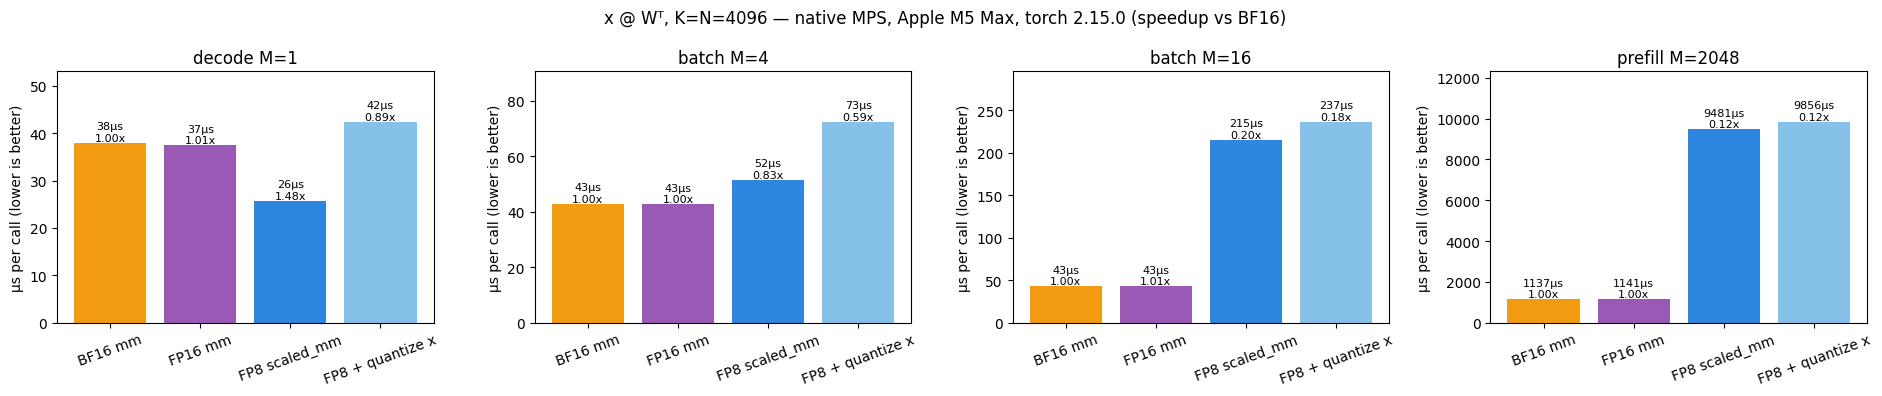

In [16]:
def bench_us(fn, warmup: int = 20, iters: int = 100, repeats: int = 7) -> float:
    """Median microseconds per call, synchronizing MPS around each timed batch."""
    for _ in range(warmup):
        fn()
    torch.mps.synchronize()
    runs = []
    for _ in range(repeats):
        t0 = time.perf_counter()
        for _ in range(iters):
            fn()
        torch.mps.synchronize()
        runs.append((time.perf_counter() - t0) / iters * 1e6)
    return float(np.median(runs))


assert DEV == "mps", "speed numbers are only meaningful on native MPS"
W32 = torch.randn(4096, 4096, device=DEV) * 0.02
w_bf, w_h = W32.bfloat16(), W32.half()
w8, sw = fp8_tensorwise(W32)
w8_t = w8.t()


def fp8_linear_dynamic(x: torch.Tensor) -> torch.Tensor:
    """Quantize activation x [M, K] on the fly, then x8 @ w8ᵀ -> [M, N] bf16."""
    x8, sx = fp8_tensorwise(x)
    return F.scaled_mm(x8, w8_t, sx, ST.TensorWise, sw, ST.TensorWise)


bench_us(lambda: torch.randn(1, 4096, device=DEV).bfloat16() @ w_bf.t())  # warm up GPU clocks, discard
timings: dict[str, dict[str, float]] = {}
for label, m in {"decode M=1": 1, "batch M=4": 4, "batch M=16": 16, "prefill M=2048": 2048}.items():
    x = torch.randn(m, 4096, device=DEV)
    x_bf, x_h = x.bfloat16(), x.half()
    x8, sx = fp8_tensorwise(x)
    timings[label] = {
        "BF16 mm": bench_us(lambda: x_bf @ w_bf.t()),
        "FP16 mm": bench_us(lambda: x_h @ w_h.t()),
        "FP8 scaled_mm": bench_us(lambda: F.scaled_mm(x8, w8_t, sx, ST.TensorWise, sw, ST.TensorWise)),
        "FP8 + quantize x": bench_us(lambda: fp8_linear_dynamic(x)),
    }
    row = "  ".join(f"{k}={v:8.1f}µs" for k, v in timings[label].items())
    print(f"{label:15s} {row}")

op_colors = [FMT_COLORS["BF16"], FMT_COLORS["FP16"], FMT_COLORS["FP8 E4M3FN"], "#85c1e9"]
fig, axes = plt.subplots(1, 4, figsize=(19, 4))
for ax, (label, t) in zip(axes, timings.items(), strict=True):
    bars = ax.bar(range(len(t)), t.values(), color=op_colors)
    base = t["BF16 mm"]
    ax.bar_label(bars, labels=[f"{v:.0f}µs\n{base / v:.2f}x" for v in t.values()], fontsize=8)
    ax.set_xticks(range(len(t)), t.keys(), rotation=20)
    ax.set_title(label)
    ax.set_ylabel("µs per call (lower is better)")
    ax.margins(y=0.25)
fig.suptitle(f"x @ Wᵀ, K=N=4096 — native MPS, {CHIP}, torch {torch.__version__} (speedup vs BF16)")
fig.tight_layout()
save(fig, "01_impact_speed.png")

## Findings (torch 2.15.0, macOS 26.7.1, Apple Silicon)

| Check on MPS | `float8_e4m3fn` | `float8_e5m2` |
|---|---|---|
| Format math (CPU, `finfo`, bit decode) | ✅ max 448, 8 steps per power of 2 | ✅ max 57344, 4 steps per power of 2 |
| Cast to MPS tensor | ✅ | ❌ `Undefined type Float8_e5m2` |
| Elementwise ops (`a + a`) | ❌ no Metal kernel | ❌ |
| `F.scaled_mm` tensorwise / rowwise (incl. M=1 decode) | ✅ **native** | ❌ |
| Block-wise / MX scaling | ❌ | ❌ |
| Legacy `torch._scaled_mm` | ❌ not implemented for MPS | ❌ |

**Takeaways**
- Both formats exist in PyTorch and are bit-identical everywhere, but **on MPS only `e4m3fn` is supported** — there's no choice here.
- FP8 on MPS is a *storage + matmul* format: you can cast and run `F.scaled_mm`, but not do general arithmetic.
- Use the new `F.scaled_mm` API; the legacy `_scaled_mm` isn't wired up for MPS.
- New in 2.15 is the **MPS backend support**, not FP8 itself (dtypes since 2.1, `F.scaled_mm` since 2.10).
- Casting saturates silently at the format max → scaling (next notebook) is essential.

**Impact on this Mac (M5 Max)**
- Memory: exactly **½ of BF16** (16 MiB vs 32 MiB for a 4096² weight); scale overhead is 4 bytes.
- Accuracy: ~**3.7%** matmul error vs ~0.3% for BF16 — fine for many inference uses, needs validation per model.
- Speed: **~1.5x faster than BF16 only for M=1 decode**, and only with pre-quantized inputs — quantizing the
  activation on every call (unfused) makes it ~0.9x. ~0.85x at M=4, and **5–8x slower** for M ≥ 16 and prefill.
  On MPS, FP8 today is a *memory/bandwidth* win for single-stream decode, not a general speedup.